In [84]:
import pandas as pd

df = pd.read_csv('/content/antenna_fault.csv')

print(df.shape)
display(df.head())

(2688, 17)


,Length,Width,Height,Permittivity,Conductivity,Bend,Feed,S11,VSWR,Gain,Efficiency,Bandwidth,WiFi Fault,BT Fault,WiFi Status,BT Status,epsilon_r
0,46.72,38.62,1.46,1.51,12210.65,0.56,-10.27,-7.09,3.41,5.09,62.26,102.74,Cracks,Cracks,Fault,Fault,3.90
1,40.32,36.17,1.30,1.61,9589.73,0.48,-17.33,-7.92,2.47,5.17,66.61,96.06,Rupture_Coupure,No_Fault,Fault,Normal,3.03
2,43.84,35.89,1.17,1.53,4067.44,0.99,-11.95,-18.97,3.20,5.07,83.42,150.03,Bending,Strong_Flexion,Fault,Fault,3.65
3,43.77,39.46,1.26,1.88,13052.58,0.67,-10.07,-12.89,1.72,3.83,42.22,54.23,Body_Effect,Coupure,Fault,Fault,3.51
4,46.48,39.66,1.30,2.44,12682.11,1.08,-17.57,-22.94,1.44,3.48,77.39,93.00,Strong_Flexion,No_Fault,Fault,Normal,2.06


In [85]:
# 1. Dataset dimensions
print("Dataset Shape:", df.shape)

# 2. Column names and data types
print("\nColumn Data Types:")
display(df.dtypes)

# 3. Statistical summary of numerical columns
print("\nNumerical Data Summary:")
display(df.describe().T)

# 4. Unique values in categorical columns
print("\nCategorical Column Values:")

categorical_cols = df.select_dtypes(
    include=['object', 'category']
).columns

for col in categorical_cols:
    print(f"\n{col}")
    print(df[col].value_counts())

Dataset Shape: (2688, 17)

Column Data Types:


,0
Length,float64
Width,float64
Height,float64
Permittivity,float64
Conductivity,float64
Bend,float64
Feed,float64
S11,float64
VSWR,float64
Gain,float64



Numerical Data Summary:


,count,mean,std,min,25%,50%,75%,max
Length,2688.0,45.040193,2.852841,40.01,42.6000,45.060,47.4525,49.99
Width,2688.0,34.834922,2.881098,30.01,32.3375,34.715,37.2100,39.99
Height,2688.0,1.195725,0.229659,0.80,1.0000,1.200,1.3900,1.60
Permittivity,2688.0,1.985588,0.286953,1.50,1.7400,1.990,2.2300,2.50
Conductivity,2688.0,8852.083810,3543.216290,3013.71,5649.9500,8965.210,11990.4700,14998.36
Bend,2688.0,0.664364,0.318201,0.10,0.4000,0.690,0.9300,1.20
Feed,2688.0,-15.145205,5.775435,-25.00,-20.1675,-15.180,-10.1200,-5.00
S11,2688.0,-13.493899,6.567709,-25.00,-19.2500,-13.380,-7.6000,-3.02
VSWR,2688.0,2.667411,0.905921,1.00,1.8800,2.790,3.4700,4.00
Gain,2688.0,2.373166,2.110233,-0.99,0.4700,2.390,4.2200,5.99



Categorical Column Values:

WiFi Fault
WiFi Fault
Cracks                      378
Rupture_Coupure             378
Bending                     378
Body_Effect                 378
Strong_Flexion              378
Humidity_Sweat              378
Conductivity_Degradation    378
No_Fault                     42
Name: count, dtype: int64

BT Fault
BT Fault
No_Fault                    336
Cracks                      294
Strong_Flexion              294
Coupure                     294
Conductivity_Degradation    294
Body_Effect                 294
Bending                     294
Humidity_or_Sweat           294
Rupture                     294
Name: count, dtype: int64

WiFi Status
WiFi Status
Fault     2646
Normal      42
Name: count, dtype: int64

BT Status
BT Status
Fault     2352
Normal     336
Name: count, dtype: int64


BT Fault = No_Fault
        ↓
   BT Status = Normal

BT Fault ≠ No_Fault
        ↓
    BT Status = Fault

In [86]:
# Check relationship between fault types and status

print("BT Fault vs BT Status")
display(pd.crosstab(
    df["BT Fault"],
    df["BT Status"]
))

print("\nWiFi Fault vs WiFi Status")
display(pd.crosstab(
    df["WiFi Fault"],
    df["WiFi Status"]
))

BT Fault vs BT Status


BT Status,Fault,Normal
BT Fault,,
Bending,294,0
Body_Effect,294,0
Conductivity_Degradation,294,0
Coupure,294,0
Cracks,294,0
Humidity_or_Sweat,294,0
No_Fault,0,336
Rupture,294,0
Strong_Flexion,294,0



WiFi Fault vs WiFi Status


WiFi Status,Fault,Normal
WiFi Fault,,
Bending,378,0
Body_Effect,378,0
Conductivity_Degradation,378,0
Cracks,378,0
Humidity_Sweat,378,0
No_Fault,0,42
Rupture_Coupure,378,0
Strong_Flexion,378,0


In [87]:
# Check whether WiFi information reveals BT Status

print("BT Status vs WiFi Status")
display(pd.crosstab(df["WiFi Status"], df["BT Status"]))

print("\nBT Status vs WiFi Fault")
display(pd.crosstab(df["WiFi Fault"], df["BT Status"]))

print("\nBT Status vs BT Fault")
display(pd.crosstab(df["BT Fault"], df["BT Status"]))

BT Status vs WiFi Status


BT Status,Fault,Normal
WiFi Status,,
Fault,2352,294
Normal,0,42



BT Status vs WiFi Fault


BT Status,Fault,Normal
WiFi Fault,,
Bending,336,42
Body_Effect,336,42
Conductivity_Degradation,336,42
Cracks,336,42
Humidity_Sweat,336,42
No_Fault,0,42
Rupture_Coupure,336,42
Strong_Flexion,336,42



BT Status vs BT Fault


BT Status,Fault,Normal
BT Fault,,
Bending,294,0
Body_Effect,294,0
Conductivity_Degradation,294,0
Coupure,294,0
Cracks,294,0
Humidity_or_Sweat,294,0
No_Fault,0,336
Rupture,294,0
Strong_Flexion,294,0


In [88]:
# Select numerical features
numerical_features = [
    'Length', 'Width', 'Height',
    'Permittivity', 'Conductivity',
    'Bend', 'Feed', 'S11', 'VSWR',
    'Gain', 'Efficiency', 'Bandwidth',
    'epsilon_r'
]

# Compare feature averages by BT Status
comparison = df.groupby('BT Status')[numerical_features].mean().T

comparison['Difference'] = (
    comparison['Fault'] - comparison['Normal']
)

display(comparison.round(3))

BT Status,Fault,Normal,Difference
Length,45.060,44.899,0.162
Width,34.809,35.020,-0.211
Height,1.193,1.212,-0.019
Permittivity,1.985,1.991,-0.006
Conductivity,8772.834,9406.830,-633.995
Bend,0.662,0.682,-0.021
Feed,-15.182,-14.888,-0.294
S11,-13.122,-16.094,2.972
VSWR,2.772,1.932,0.841
Gain,2.293,2.933,-0.639


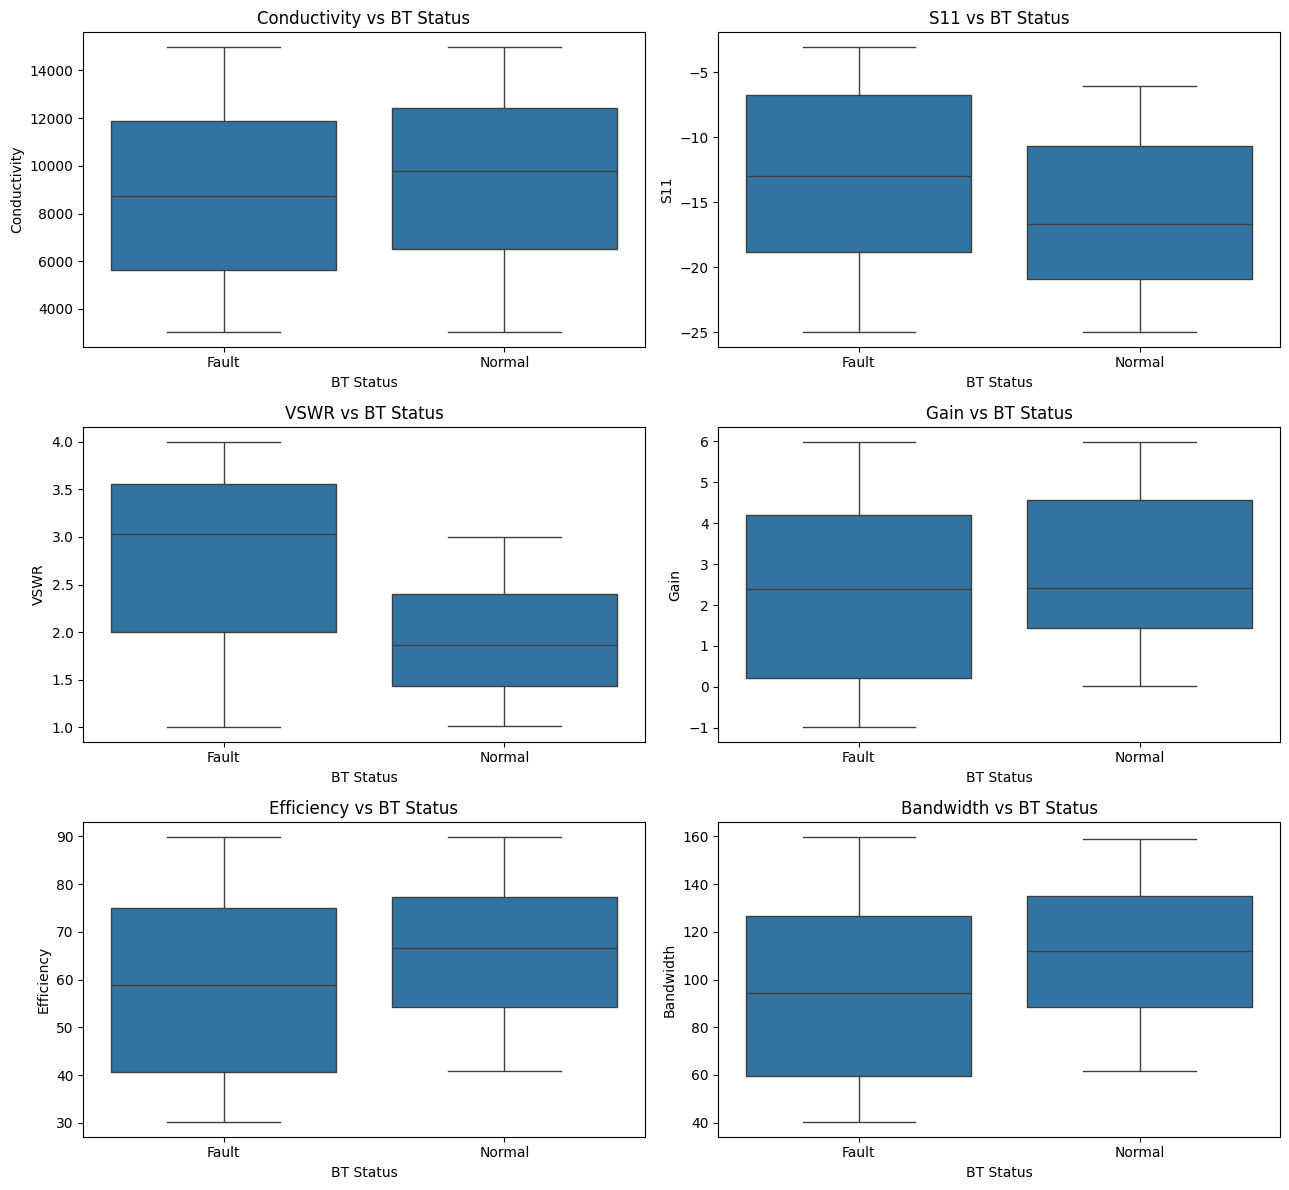

In [89]:
import matplotlib.pyplot as plt
import seaborn as sns

features = [
    'Conductivity',
    'S11',
    'VSWR',
    'Gain',
    'Efficiency',
    'Bandwidth'
]

fig, axes = plt.subplots(3, 2, figsize=(13, 12))

for feature, ax in zip(features, axes.flatten()):
    sns.boxplot(
        data=df,
        x='BT Status',
        y=feature,
        ax=ax
    )
    ax.set_title(f'{feature} vs BT Status')

plt.tight_layout()
plt.show()

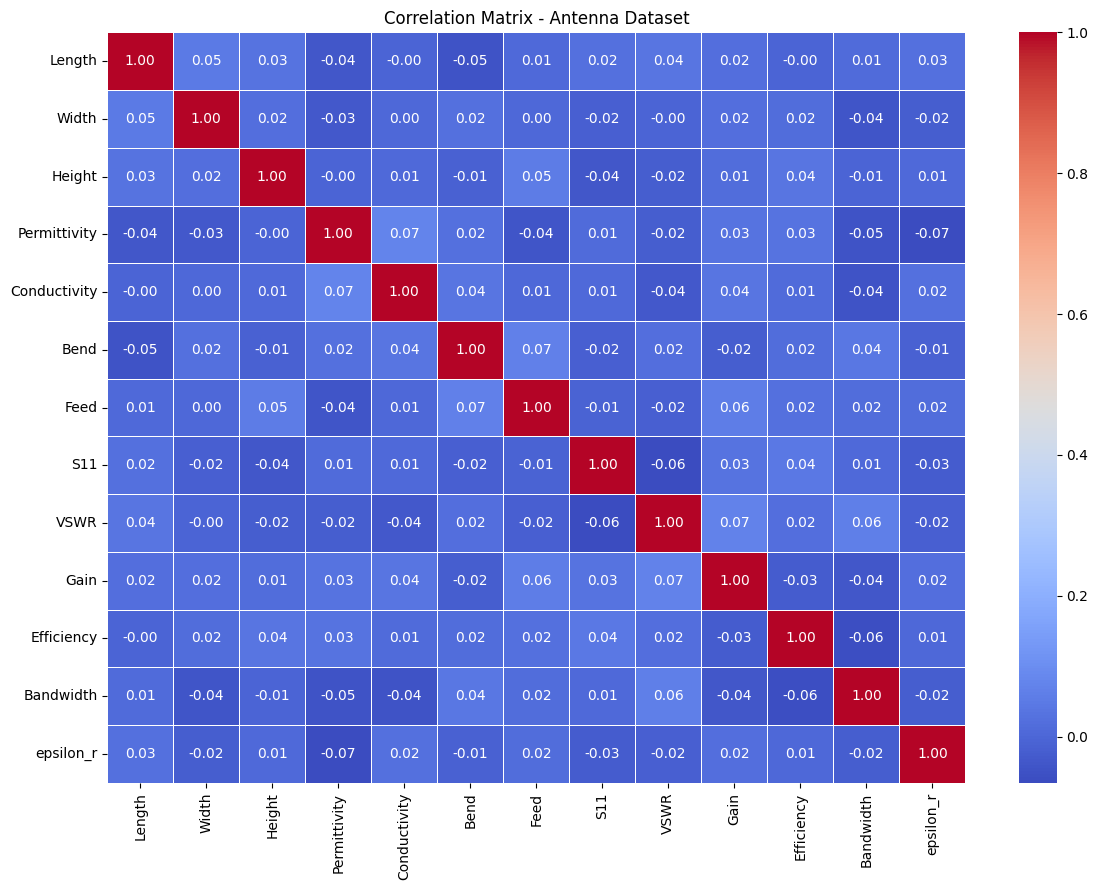

In [90]:
import seaborn as sns
import matplotlib.pyplot as plt

# Select numerical features
numerical_features = [
    'Length', 'Width', 'Height',
    'Permittivity', 'Conductivity',
    'Bend', 'Feed', 'S11', 'VSWR',
    'Gain', 'Efficiency', 'Bandwidth',
    'epsilon_r'
]

# Calculate correlation matrix
corr = df[numerical_features].corr()

# Plot correlation heatmap
plt.figure(figsize=(12, 9))

sns.heatmap(
    corr,
    annot=True,
    cmap='coolwarm',
    fmt='.2f',
    linewidths=0.5
)

plt.title("Correlation Matrix - Antenna Dataset")
plt.tight_layout()
plt.show()


In [91]:
print("BT Status distribution:")
print(df['BT Status'].value_counts())

print("\nUnique target values:")
print(df['BT Status'].unique())

print("\nNumerical feature count:")
print(len(numerical_features))

BT Status distribution:
BT Status
Fault     2352
Normal     336
Name: count, dtype: int64

Unique target values:
['Fault' 'Normal']

Numerical feature count:
13


In [92]:
print("Total duplicate rows:", df.duplicated().sum())
print(
    "Duplicate numerical feature records:",
    df.duplicated(subset=numerical_features).sum()
)

Total duplicate rows: 1636
Duplicate numerical feature records: 1636


In [93]:
# Group identical numerical observations
duplicate_groups = (
    df.groupby(numerical_features)['BT Status']
    .nunique()
)

# Count groups having conflicting labels
conflicting_groups = duplicate_groups[
    duplicate_groups > 1
]

print("Total unique numerical combinations:",
      duplicate_groups.shape[0])

print("Groups with conflicting BT Status:",
      len(conflicting_groups))

Total unique numerical combinations: 1052
Groups with conflicting BT Status: 0


In [94]:
# Examine how frequently each unique record occurs
frequency = df.groupby(
    numerical_features + ['BT Status']
).size().reset_index(name='Frequency')

print("Most frequently repeated records:")
display(frequency.sort_values(
    'Frequency', ascending=False
).head(10))

Most frequently repeated records:


,Length,Width,Height,Permittivity,Conductivity,Bend,Feed,S11,VSWR,Gain,Efficiency,Bandwidth,epsilon_r,BT Status,Frequency
562,45.50,31.83,1.55,2.43,14710.04,0.16,-11.41,-5.74,1.93,3.34,70.17,55.51,2.89,Fault,7
674,46.38,30.37,1.59,2.31,7951.19,0.69,-19.66,-14.63,3.06,5.08,87.36,119.64,2.37,Fault,7
381,43.74,37.38,1.47,2.48,3145.94,0.22,-24.31,-23.72,3.86,0.56,35.02,72.40,3.69,Fault,7
276,42.78,37.69,1.47,1.84,10217.97,1.13,-7.44,-20.01,2.71,-0.91,88.05,134.67,2.77,Fault,7
663,46.32,34.80,1.45,2.11,9731.05,0.43,-5.93,-3.30,3.99,4.48,89.37,105.11,2.76,Fault,7
849,48.12,30.09,1.59,1.52,10290.85,1.12,-8.37,-18.17,3.47,1.75,59.99,83.59,3.64,Fault,7
873,48.29,30.55,0.82,1.68,6304.00,0.74,-14.19,-18.50,2.89,5.24,71.60,42.82,2.19,Fault,7
369,43.60,35.99,1.26,2.02,10428.53,0.23,-22.75,-18.48,3.16,1.72,30.07,135.57,2.19,Fault,6
615,45.85,32.32,1.14,1.71,4779.76,0.40,-22.86,-21.83,3.91,5.03,89.96,123.10,2.72,Fault,6
866,48.24,31.08,1.22,2.03,11279.81,0.19,-20.39,-8.83,3.16,2.59,32.77,42.22,2.60,Fault,6


In [95]:
# Step 1: Remove exact duplicate records
df_clean = df.drop_duplicates().copy()

# Step 2: Reset index
df_clean.reset_index(drop=True, inplace=True)

# Step 3: Check dimensions
print("Original Dataset:", df.shape)
print("Cleaned Dataset:", df_clean.shape)

# Step 4: Check duplicate records again
print(
    "Remaining duplicates:",
    df_clean.duplicated().sum()
)

# Step 5: Check BT Status distribution
print("\nBT Status Distribution:")
print(df_clean['BT Status'].value_counts())

# Step 6: Check class percentages
print("\nBT Status Percentage:")
print(
    df_clean['BT Status']
    .value_counts(normalize=True)
    .mul(100)
    .round(2)
)

Original Dataset: (2688, 17)
Cleaned Dataset: (1052, 17)
Remaining duplicates: 0

BT Status Distribution:
BT Status
Fault     893
Normal    159
Name: count, dtype: int64

BT Status Percentage:
BT Status
Fault     84.89
Normal    15.11
Name: proportion, dtype: float64


In [96]:
numerical_features = [
    'Length', 'Width', 'Height',
    'Permittivity', 'Conductivity',
    'Bend', 'Feed', 'S11', 'VSWR',
    'Gain', 'Efficiency', 'Bandwidth',
    'epsilon_r'
]
# Separate input features and target

X = df_clean[numerical_features]

y = df_clean['BT Status']

# Verify dimensions

print("Input Features (X):", X.shape)
print("Target Variable (y):", y.shape)

print("\nInput Feature Names:")
print(X.columns.tolist())

print("\nTarget Distribution:")
print(y.value_counts())

from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print("Training Features:", X_train.shape)
print("Testing Features:", X_test.shape)

print("\nTraining Target Distribution:")
print(y_train.value_counts())

print("\nTesting Target Distribution:")
print(y_test.value_counts())


Input Features (X): (1052, 13)
Target Variable (y): (1052,)

Input Feature Names:
['Length', 'Width', 'Height', 'Permittivity', 'Conductivity', 'Bend', 'Feed', 'S11', 'VSWR', 'Gain', 'Efficiency', 'Bandwidth', 'epsilon_r']

Target Distribution:
BT Status
Fault     893
Normal    159
Name: count, dtype: int64
Training Features: (841, 13)
Testing Features: (211, 13)

Training Target Distribution:
BT Status
Fault     714
Normal    127
Name: count, dtype: int64

Testing Target Distribution:
BT Status
Fault     179
Normal     32
Name: count, dtype: int64


In [97]:
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegression
from sklearn.neighbors import KNeighborsClassifier
from sklearn.svm import SVC

# Logistic Regression pipeline
logistic_pipeline = Pipeline([
    ('scaler', StandardScaler()),
    ('model', LogisticRegression(max_iter=2000))
])

# KNN pipeline
knn_pipeline = Pipeline([
    ('scaler', StandardScaler()),
    ('model', KNeighborsClassifier(n_neighbors=5))
])

# SVM pipeline
svm_pipeline = Pipeline([
    ('scaler', StandardScaler()),
    ('model', SVC(probability=True, random_state=42))
])

print("Three preprocessing pipelines created successfully.")

Three preprocessing pipelines created successfully.


In [98]:
# Train the Logistic Regression pipeline
logistic_pipeline.fit(X_train, y_train)

# Predict class labels for test data
y_pred_lr = logistic_pipeline.predict(X_test)

# Predict probabilities for ROC-AUC calculation
y_prob_lr = logistic_pipeline.predict_proba(X_test)

print("Logistic Regression training completed.")
print("Model classes:", logistic_pipeline.classes_)
print("Predictions generated:", len(y_pred_lr))
print("Probability output shape:", y_prob_lr.shape)

Logistic Regression training completed.
Model classes: ['Fault' 'Normal']
Predictions generated: 211
Probability output shape: (211, 2)


In [99]:
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    matthews_corrcoef,
    roc_auc_score,
    confusion_matrix,
    classification_report
)

# Fault is our positive class
fault_probability = y_prob_lr[:, 0]

# Calculate metrics
lr_accuracy = accuracy_score(y_test, y_pred_lr)
lr_precision = precision_score(
    y_test, y_pred_lr, pos_label='Fault'
)
lr_recall = recall_score(
    y_test, y_pred_lr, pos_label='Fault'
)
lr_f1 = f1_score(
    y_test, y_pred_lr, pos_label='Fault'
)
lr_mcc = matthews_corrcoef(y_test, y_pred_lr)

# Convert actual labels into binary values for ROC-AUC
y_test_binary = (y_test == 'Fault').astype(int)

lr_auc = roc_auc_score(
    y_test_binary, fault_probability
)

print("LOGISTIC REGRESSION - EVALUATION")
print("--------------------------------")
print(f"Accuracy  : {lr_accuracy:.4f}")
print(f"AUC       : {lr_auc:.4f}")
print(f"Precision : {lr_precision:.4f}")
print(f"Recall    : {lr_recall:.4f}")
print(f"F1 Score  : {lr_f1:.4f}")
print(f"MCC       : {lr_mcc:.4f}")

print("\nConfusion Matrix:")
print(confusion_matrix(
    y_test, y_pred_lr,
    labels=['Fault', 'Normal']
))

print("\nClassification Report:")
print(classification_report(y_test, y_pred_lr))

LOGISTIC REGRESSION - EVALUATION
--------------------------------
Accuracy  : 0.8673
AUC       : 0.8684
Precision : 0.8995
Recall    : 0.9497
F1 Score  : 0.9239
MCC       : 0.4178

Confusion Matrix:
[[170   9]
 [ 19  13]]

Classification Report:
              precision    recall  f1-score   support

       Fault       0.90      0.95      0.92       179
      Normal       0.59      0.41      0.48        32

    accuracy                           0.87       211
   macro avg       0.75      0.68      0.70       211
weighted avg       0.85      0.87      0.86       211



In [100]:
from sklearn.tree import DecisionTreeClassifier
from sklearn.pipeline import Pipeline

decision_tree_pipeline = Pipeline([
    ('model', DecisionTreeClassifier(
        random_state=42
    ))
])

# Train
decision_tree_pipeline.fit(X_train, y_train)

# Predict
y_pred_dt = decision_tree_pipeline.predict(X_test)

# Predict probabilities
y_prob_dt = decision_tree_pipeline.predict_proba(X_test)

print("Decision Tree training completed.")
print("Model classes:", decision_tree_pipeline.classes_)
print("Predictions generated:", len(y_pred_dt))
print("Probability output shape:", y_prob_dt.shape)

Decision Tree training completed.
Model classes: ['Fault' 'Normal']
Predictions generated: 211
Probability output shape: (211, 2)


In [101]:
# Extract probability of Fault
fault_probability_dt = y_prob_dt[:, 0]

# Calculate metrics
dt_accuracy = accuracy_score(y_test, y_pred_dt)

dt_precision = precision_score(
    y_test, y_pred_dt, pos_label='Fault'
)

dt_recall = recall_score(
    y_test, y_pred_dt, pos_label='Fault'
)

dt_f1 = f1_score(
    y_test, y_pred_dt, pos_label='Fault'
)

dt_mcc = matthews_corrcoef(y_test, y_pred_dt)

dt_auc = roc_auc_score(
    y_test_binary, fault_probability_dt
)

print("DECISION TREE - EVALUATION")
print("--------------------------------")
print(f"Accuracy  : {dt_accuracy:.4f}")
print(f"AUC       : {dt_auc:.4f}")
print(f"Precision : {dt_precision:.4f}")
print(f"Recall    : {dt_recall:.4f}")
print(f"F1 Score  : {dt_f1:.4f}")
print(f"MCC       : {dt_mcc:.4f}")

print("\nConfusion Matrix:")
print(confusion_matrix(
    y_test, y_pred_dt,
    labels=['Fault', 'Normal']
))

print("\nClassification Report:")
print(classification_report(y_test, y_pred_dt))

DECISION TREE - EVALUATION
--------------------------------
Accuracy  : 0.9953
AUC       : 0.9844
Precision : 0.9944
Recall    : 1.0000
F1 Score  : 0.9972
MCC       : 0.9815

Confusion Matrix:
[[179   0]
 [  1  31]]

Classification Report:
              precision    recall  f1-score   support

       Fault       0.99      1.00      1.00       179
      Normal       1.00      0.97      0.98        32

    accuracy                           1.00       211
   macro avg       1.00      0.98      0.99       211
weighted avg       1.00      1.00      1.00       211



In [102]:
# Train KNN
knn_pipeline.fit(X_train, y_train)

# Predict class labels
y_pred_knn = knn_pipeline.predict(X_test)

# Predict class probabilities
y_prob_knn = knn_pipeline.predict_proba(X_test)

print("KNN training completed.")
print("Model classes:", knn_pipeline.classes_)
print("Predictions generated:", len(y_pred_knn))
print("Probability output shape:", y_prob_knn.shape)

# Extract probability of Fault
fault_probability_knn = y_prob_knn[:, 0]

# Calculate metrics
knn_accuracy = accuracy_score(y_test, y_pred_knn)

knn_precision = precision_score(
    y_test, y_pred_knn, pos_label='Fault'
)

knn_recall = recall_score(
    y_test, y_pred_knn, pos_label='Fault'
)

knn_f1 = f1_score(
    y_test, y_pred_knn, pos_label='Fault'
)

knn_mcc = matthews_corrcoef(y_test, y_pred_knn)

knn_auc = roc_auc_score(
    y_test_binary, fault_probability_knn
)

print("KNN - EVALUATION")
print("--------------------------------")
print(f"Accuracy  : {knn_accuracy:.4f}")
print(f"AUC       : {knn_auc:.4f}")
print(f"Precision : {knn_precision:.4f}")
print(f"Recall    : {knn_recall:.4f}")
print(f"F1 Score  : {knn_f1:.4f}")
print(f"MCC       : {knn_mcc:.4f}")

print("\nConfusion Matrix:")
print(confusion_matrix(
    y_test, y_pred_knn,
    labels=['Fault', 'Normal']
))

print("\nClassification Report:")
print(classification_report(y_test, y_pred_knn))

KNN training completed.
Model classes: ['Fault' 'Normal']
Predictions generated: 211
Probability output shape: (211, 2)
KNN - EVALUATION
--------------------------------
Accuracy  : 0.8815
AUC       : 0.7857
Precision : 0.8969
Recall    : 0.9721
F1 Score  : 0.9330
MCC       : 0.4574

Confusion Matrix:
[[174   5]
 [ 20  12]]

Classification Report:
              precision    recall  f1-score   support

       Fault       0.90      0.97      0.93       179
      Normal       0.71      0.38      0.49        32

    accuracy                           0.88       211
   macro avg       0.80      0.67      0.71       211
weighted avg       0.87      0.88      0.87       211



In [103]:
from sklearn.naive_bayes import GaussianNB

# Create Gaussian Naive Bayes pipeline
naive_bayes_pipeline = Pipeline([
    ('model', GaussianNB())
])

# Train
naive_bayes_pipeline.fit(X_train, y_train)

# Predict
y_pred_nb = naive_bayes_pipeline.predict(X_test)

# Predict probabilities
y_prob_nb = naive_bayes_pipeline.predict_proba(X_test)

print("Gaussian Naive Bayes training completed.")
print("Model classes:", naive_bayes_pipeline.classes_)
print("Predictions generated:", len(y_pred_nb))
print("Probability output shape:", y_prob_nb.shape)

Gaussian Naive Bayes training completed.
Model classes: ['Fault' 'Normal']
Predictions generated: 211
Probability output shape: (211, 2)


In [104]:
# Extract probability of Fault
fault_probability_nb = y_prob_nb[:, 0]

# Calculate metrics
nb_accuracy = accuracy_score(y_test, y_pred_nb)

nb_precision = precision_score(
    y_test, y_pred_nb, pos_label='Fault'
)

nb_recall = recall_score(
    y_test, y_pred_nb, pos_label='Fault'
)

nb_f1 = f1_score(
    y_test, y_pred_nb, pos_label='Fault'
)

nb_mcc = matthews_corrcoef(y_test, y_pred_nb)

nb_auc = roc_auc_score(
    y_test_binary, fault_probability_nb
)

print("GAUSSIAN NAIVE BAYES - EVALUATION")
print("--------------------------------")
print(f"Accuracy  : {nb_accuracy:.4f}")
print(f"AUC       : {nb_auc:.4f}")
print(f"Precision : {nb_precision:.4f}")
print(f"Recall    : {nb_recall:.4f}")
print(f"F1 Score  : {nb_f1:.4f}")
print(f"MCC       : {nb_mcc:.4f}")

print("\nConfusion Matrix:")
print(confusion_matrix(
    y_test, y_pred_nb,
    labels=['Fault', 'Normal']
))

print("\nClassification Report:")
print(classification_report(y_test, y_pred_nb))

GAUSSIAN NAIVE BAYES - EVALUATION
--------------------------------
Accuracy  : 0.8957
AUC       : 0.9433
Precision : 0.8945
Recall    : 0.9944
F1 Score  : 0.9418
MCC       : 0.5237

Confusion Matrix:
[[178   1]
 [ 21  11]]

Classification Report:
              precision    recall  f1-score   support

       Fault       0.89      0.99      0.94       179
      Normal       0.92      0.34      0.50        32

    accuracy                           0.90       211
   macro avg       0.91      0.67      0.72       211
weighted avg       0.90      0.90      0.87       211



In [105]:
# Train SVM
svm_pipeline.fit(X_train, y_train)

# Predict class labels
y_pred_svm = svm_pipeline.predict(X_test)

# Predict class probabilities
y_prob_svm = svm_pipeline.predict_proba(X_test)

print("SVM training completed.")
print("Model classes:", svm_pipeline.classes_)
print("Predictions generated:", len(y_pred_svm))
print("Probability output shape:", y_prob_svm.shape)

SVM training completed.
Model classes: ['Fault' 'Normal']
Predictions generated: 211
Probability output shape: (211, 2)


In [106]:
# Extract probability of Fault
fault_probability_svm = y_prob_svm[:, 0]

# Calculate metrics
svm_accuracy = accuracy_score(y_test, y_pred_svm)

svm_precision = precision_score(
    y_test, y_pred_svm, pos_label='Fault'
)

svm_recall = recall_score(
    y_test, y_pred_svm, pos_label='Fault'
)

svm_f1 = f1_score(
    y_test, y_pred_svm, pos_label='Fault'
)

svm_mcc = matthews_corrcoef(y_test, y_pred_svm)

svm_auc = roc_auc_score(
    y_test_binary, fault_probability_svm
)

print("SVM - EVALUATION")
print("--------------------------------")
print(f"Accuracy  : {svm_accuracy:.4f}")
print(f"AUC       : {svm_auc:.4f}")
print(f"Precision : {svm_precision:.4f}")
print(f"Recall    : {svm_recall:.4f}")
print(f"F1 Score  : {svm_f1:.4f}")
print(f"MCC       : {svm_mcc:.4f}")

print("\nConfusion Matrix:")
print(confusion_matrix(
    y_test, y_pred_svm,
    labels=['Fault', 'Normal']
))

print("\nClassification Report:")
print(classification_report(y_test, y_pred_svm))

SVM - EVALUATION
--------------------------------
Accuracy  : 0.9100
AUC       : 0.9223
Precision : 0.9124
Recall    : 0.9888
F1 Score  : 0.9491
MCC       : 0.6030

Confusion Matrix:
[[177   2]
 [ 17  15]]

Classification Report:
              precision    recall  f1-score   support

       Fault       0.91      0.99      0.95       179
      Normal       0.88      0.47      0.61        32

    accuracy                           0.91       211
   macro avg       0.90      0.73      0.78       211
weighted avg       0.91      0.91      0.90       211



In [107]:
import pandas as pd

results = pd.DataFrame({
    'Model': [
        'Logistic Regression',
        'Decision Tree',
        'KNN',
        'Gaussian Naive Bayes',
        'SVM'
    ],
    'Accuracy': [
        lr_accuracy, dt_accuracy, knn_accuracy,
        nb_accuracy, svm_accuracy
    ],
    'AUC': [
        lr_auc, dt_auc, knn_auc, nb_auc, svm_auc
    ],
    'Precision': [
        lr_precision, dt_precision, knn_precision,
        nb_precision, svm_precision
    ],
    'Recall': [
        lr_recall, dt_recall, knn_recall,
        nb_recall, svm_recall
    ],
    'F1 Score': [
        lr_f1, dt_f1, knn_f1, nb_f1, svm_f1
    ],
    'MCC': [
        lr_mcc, dt_mcc, knn_mcc, nb_mcc, svm_mcc
    ]
})

results = results.sort_values(
    by='MCC', ascending=False
).reset_index(drop=True)

print(results.round(4))

                  Model  Accuracy     AUC  Precision  Recall  F1 Score     MCC
0         Decision Tree    0.9953  0.9844     0.9944  1.0000    0.9972  0.9815
1                   SVM    0.9100  0.9223     0.9124  0.9888    0.9491  0.6030
2  Gaussian Naive Bayes    0.8957  0.9433     0.8945  0.9944    0.9418  0.5237
3                   KNN    0.8815  0.7857     0.8969  0.9721    0.9330  0.4574
4   Logistic Regression    0.8673  0.8684     0.8995  0.9497    0.9239  0.4178


In [108]:
from sklearn.metrics import (
    make_scorer,
    precision_score,
    recall_score,
    f1_score
)

from sklearn.model_selection import (
    StratifiedKFold,
    cross_validate
)

from sklearn.tree import DecisionTreeClassifier

# 1. Define 5-fold stratified cross-validation
cv = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

# 2. Define Decision Tree
dt_cv_model = DecisionTreeClassifier(
    random_state=42
)

# 3. Configure metrics with Fault as positive class
scoring = {
    'accuracy': 'accuracy',

    'precision': make_scorer(
        precision_score,
        pos_label='Fault'
    ),

    'recall': make_scorer(
        recall_score,
        pos_label='Fault'
    ),

    'f1': make_scorer(
        f1_score,
        pos_label='Fault'
    ),

    'roc_auc': 'roc_auc',
    'mcc': 'matthews_corrcoef'
}

# 4. Perform cross-validation
cv_results = cross_validate(
    dt_cv_model,
    X_train,
    y_train,
    cv=cv,
    scoring=scoring
)

# 5. Display average and standard deviation
print("DECISION TREE - 5 FOLD CROSS VALIDATION")
print("----------------------------------------")

for metric in scoring:
    scores = cv_results[f'test_{metric}']

    print(
        f"{metric.upper():10s}: "
        f"{scores.mean():.4f} +/- {scores.std():.4f}"
    )

DECISION TREE - 5 FOLD CROSS VALIDATION
----------------------------------------
ACCURACY  : 0.9988 +/- 0.0024
PRECISION : 0.9986 +/- 0.0028
RECALL    : 1.0000 +/- 0.0000
F1        : 0.9993 +/- 0.0014
ROC_AUC   : 0.9962 +/- 0.0077
MCC       : 0.9954 +/- 0.0091


In [109]:
from sklearn.svm import SVC
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler

# Create SVM pipeline
svm_cv_model = Pipeline([
    ('scaler', StandardScaler()),
    ('model', SVC(
        probability=True,
        random_state=42
    ))
])

# Perform cross-validation
svm_cv_results = cross_validate(
    svm_cv_model,
    X_train,
    y_train,
    cv=cv,
    scoring=scoring
)

# Display results
print("SVM - 5 FOLD CROSS VALIDATION")
print("--------------------------------")

for metric in scoring:
    scores = svm_cv_results[f'test_{metric}']

    print(
        f"{metric.upper():10s}: "
        f"{scores.mean():.4f} +/- {scores.std():.4f}"
    )

SVM - 5 FOLD CROSS VALIDATION
--------------------------------
ACCURACY  : 0.8918 +/- 0.0143
PRECISION : 0.8931 +/- 0.0148
RECALL    : 0.9916 +/- 0.0028
F1        : 0.9397 +/- 0.0073
ROC_AUC   : 0.9216 +/- 0.0142
MCC       : 0.4880 +/- 0.1002


In [110]:
from sklearn.neighbors import KNeighborsClassifier
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler

# Create KNN pipeline
knn_cv_model = Pipeline([
    ('scaler', StandardScaler()),
    ('model', KNeighborsClassifier(n_neighbors=5))
])

# Perform cross-validation
knn_cv_results = cross_validate(
    knn_cv_model,
    X_train,
    y_train,
    cv=cv,
    scoring=scoring
)

# Display results
print("KNN - 5 FOLD CROSS VALIDATION")
print("--------------------------------")

for metric in scoring:
    scores = knn_cv_results[f'test_{metric}']

    print(
        f"{metric.upper():10s}: "
        f"{scores.mean():.4f} +/- {scores.std():.4f}"
    )

KNN - 5 FOLD CROSS VALIDATION
--------------------------------
ACCURACY  : 0.8656 +/- 0.0225
PRECISION : 0.8852 +/- 0.0187
RECALL    : 0.9678 +/- 0.0113
F1        : 0.9245 +/- 0.0120
ROC_AUC   : 0.7990 +/- 0.0588
MCC       : 0.3420 +/- 0.1614


In [111]:
from sklearn.naive_bayes import GaussianNB

# Create Gaussian Naive Bayes model
nb_cv_model = GaussianNB()

# Perform cross-validation
nb_cv_results = cross_validate(
    nb_cv_model,
    X_train,
    y_train,
    cv=cv,
    scoring=scoring
)

# Display results
print("GAUSSIAN NAIVE BAYES - 5 FOLD CROSS VALIDATION")
print("-----------------------------------------------")

for metric in scoring:
    scores = nb_cv_results[f'test_{metric}']

    print(
        f"{metric.upper():10s}: "
        f"{scores.mean():.4f} +/- {scores.std():.4f}"
    )

GAUSSIAN NAIVE BAYES - 5 FOLD CROSS VALIDATION
-----------------------------------------------
ACCURACY  : 0.9013 +/- 0.0116
PRECISION : 0.8971 +/- 0.0130
RECALL    : 0.9986 +/- 0.0028
F1        : 0.9451 +/- 0.0059
ROC_AUC   : 0.9272 +/- 0.0223
MCC       : 0.5520 +/- 0.0692


In [112]:
from sklearn.linear_model import LogisticRegression
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler

# Create Logistic Regression pipeline
lr_cv_model = Pipeline([
    ('scaler', StandardScaler()),
    ('model', LogisticRegression(max_iter=2000))
])

# Perform cross-validation
lr_cv_results = cross_validate(
    lr_cv_model,
    X_train,
    y_train,
    cv=cv,
    scoring=scoring
)

# Display results
print("LOGISTIC REGRESSION - 5 FOLD CROSS VALIDATION")
print("----------------------------------------------")

for metric in scoring:
    scores = lr_cv_results[f'test_{metric}']

    print(
        f"{metric.upper():10s}: "
        f"{scores.mean():.4f} +/- {scores.std():.4f}"
    )

LOGISTIC REGRESSION - 5 FOLD CROSS VALIDATION
----------------------------------------------
ACCURACY  : 0.8870 +/- 0.0121
PRECISION : 0.9040 +/- 0.0148
RECALL    : 0.9706 +/- 0.0163
F1        : 0.9359 +/- 0.0066
ROC_AUC   : 0.8709 +/- 0.0373
MCC       : 0.4898 +/- 0.0831


In [113]:
# Extract the trained Decision Tree from the pipeline
dt_model = decision_tree_pipeline.named_steps['model']

# Inspect tree complexity
print("DECISION TREE STRUCTURE")
print("-----------------------")
print("Tree Depth       :", dt_model.get_depth())
print("Number of Leaves :", dt_model.get_n_leaves())
print("Number of Nodes  :", dt_model.tree_.node_count)

# Compare training and test accuracy
train_accuracy = decision_tree_pipeline.score(X_train, y_train)
test_accuracy = decision_tree_pipeline.score(X_test, y_test)

print("\nMODEL PERFORMANCE")
print("-----------------------")
print(f"Training Accuracy : {train_accuracy:.4f}")
print(f"Testing Accuracy  : {test_accuracy:.4f}")
print(f"Accuracy Gap      : {train_accuracy - test_accuracy:.4f}")

DECISION TREE STRUCTURE
-----------------------
Tree Depth       : 5
Number of Leaves : 6
Number of Nodes  : 11

MODEL PERFORMANCE
-----------------------
Training Accuracy : 1.0000
Testing Accuracy  : 0.9953
Accuracy Gap      : 0.0047


     Feature  Importance
        Gain    0.373626
         S11    0.235463
  Efficiency    0.149763
        VSWR    0.129926
   Bandwidth    0.111221
Conductivity    0.000000
Permittivity    0.000000
      Height    0.000000
       Width    0.000000
      Length    0.000000
        Feed    0.000000
        Bend    0.000000
   epsilon_r    0.000000


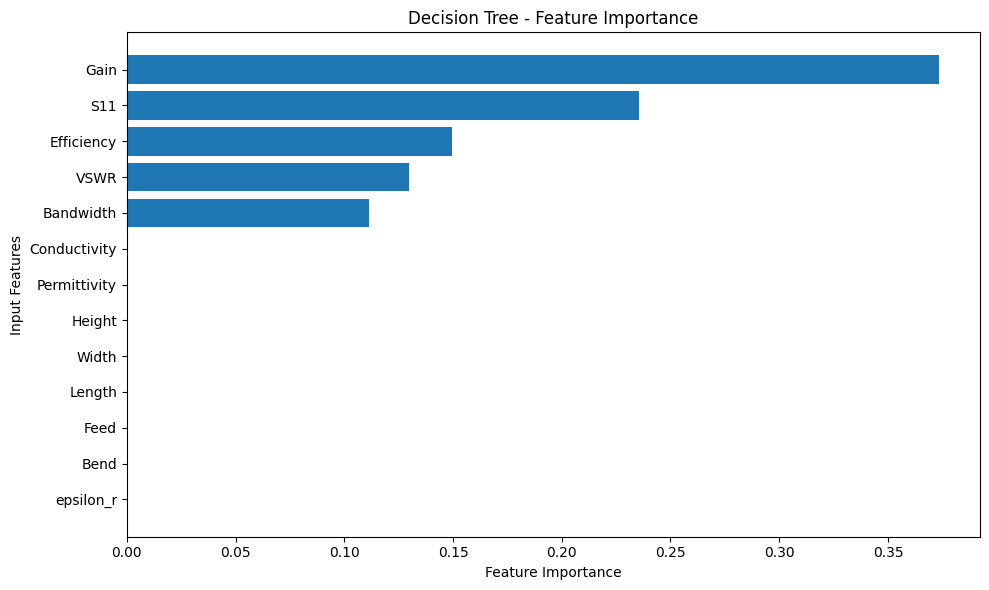

In [114]:
# Extract feature importance
feature_importance = pd.DataFrame({
    'Feature': numerical_features,
    'Importance': dt_model.feature_importances_
})

# Sort in descending order
feature_importance = feature_importance.sort_values(
    by='Importance',
    ascending=False
)

print(feature_importance.to_string(index=False))


import matplotlib.pyplot as plt

plt.figure(figsize=(10, 6))

plt.barh(
    feature_importance['Feature'],
    feature_importance['Importance']
)

plt.xlabel('Feature Importance')
plt.ylabel('Input Features')
plt.title('Decision Tree - Feature Importance')
plt.gca().invert_yaxis()

plt.tight_layout()
plt.show()

In [115]:
from sklearn.tree import export_text

tree_rules = export_text(
    dt_model,
    feature_names=numerical_features
)

print(tree_rules)

|--- VSWR <= 3.00
|   |--- Bandwidth <= 61.66
|   |   |--- class: Fault
|   |--- Bandwidth >  61.66
|   |   |--- Efficiency <= 40.41
|   |   |   |--- class: Fault
|   |   |--- Efficiency >  40.41
|   |   |   |--- S11 <= -5.96
|   |   |   |   |--- Gain <= -0.01
|   |   |   |   |   |--- class: Fault
|   |   |   |   |--- Gain >  -0.01
|   |   |   |   |   |--- class: Normal
|   |   |   |--- S11 >  -5.96
|   |   |   |   |--- class: Fault
|--- VSWR >  3.00
|   |--- class: Fault



In [116]:
# Predict the test dataset
y_pred = decision_tree_pipeline.predict(X_test)

# Identify incorrect predictions
misclassified = X_test[y_test != y_pred].copy()

# Add actual and predicted labels
misclassified['Actual_Status'] = y_test[y_test != y_pred]
misclassified['Predicted_Status'] = y_pred[y_test != y_pred]

print("MISCLASSIFIED RECORDS")
print("---------------------")
print(misclassified.to_string())

MISCLASSIFIED RECORDS
---------------------
     Length  Width  Height  Permittivity  Conductivity  Bend   Feed    S11  VSWR  Gain  Efficiency  Bandwidth  epsilon_r Actual_Status Predicted_Status
467   49.39  31.21    1.38          2.29      10453.35  0.91 -18.68 -22.85  1.45  4.84        59.7      61.59       2.62        Normal            Fault


In [117]:
# Inspect records near the Decision Tree bandwidth threshold

threshold = 61.66

near_threshold = df_clean[
    (df_clean['VSWR'] <= 3.00) &
    (df_clean['Bandwidth'] >= threshold - 2) &
    (df_clean['Bandwidth'] <= threshold + 2)
]

print("RECORDS NEAR BANDWIDTH THRESHOLD")
print("--------------------------------")
print(near_threshold[
    ['VSWR', 'Bandwidth', 'Efficiency', 'S11',
     'Gain', 'BT Status']
].sort_values('Bandwidth').to_string(index=False))

print("\nACTUAL CLASS DISTRIBUTION")
print("-------------------------")
print(near_threshold['BT Status'].value_counts())

RECORDS NEAR BANDWIDTH THRESHOLD
--------------------------------
 VSWR  Bandwidth  Efficiency    S11  Gain BT Status
 1.66      59.75       83.56 -13.46  3.93     Fault
 2.97      59.79       31.45 -12.33  0.37     Fault
 2.05      60.10       37.72 -15.64  4.86     Fault
 2.04      60.56       32.65 -10.89  5.21     Fault
 2.00      60.88       70.22  -3.74 -0.60     Fault
 1.99      60.99       34.87 -17.79  1.81     Fault
 2.07      61.25       51.05 -16.47 -0.14     Fault
 1.45      61.59       59.70 -22.85  4.84    Normal
 1.05      62.06       67.59 -24.30  1.38    Normal
 1.63      62.14       41.81 -17.24  5.45    Normal
 1.50      62.19       45.74 -22.89  0.79    Normal
 2.80      62.67       47.76  -3.02  0.22     Fault
 2.68      62.83       71.18  -4.12 -0.33     Fault
 1.17      63.03       39.07 -12.13  1.14     Fault
 2.49      63.17       76.21 -21.16 -0.83     Fault
 1.25      63.60       42.65  -9.01 -0.68     Fault

ACTUAL CLASS DISTRIBUTION
-----------------------

In [118]:
threshold = 61.66

train_bandwidth_analysis = X_train[
    ['Bandwidth', 'VSWR']
].copy()

train_bandwidth_analysis['Actual_Status'] = y_train

train_bandwidth_analysis['Bandwidth_Group'] = (
    train_bandwidth_analysis['Bandwidth']
    .apply(lambda x: 'Below/Equal 61.66' if x <= threshold
           else 'Above 61.66')
)

print(
    pd.crosstab(
        train_bandwidth_analysis['Bandwidth_Group'],
        train_bandwidth_analysis['Actual_Status']
    )
)

Actual_Status      Fault  Normal
Bandwidth_Group                 
Above 61.66          515     127
Below/Equal 61.66    199       0


In [119]:
from sklearn.tree import DecisionTreeClassifier
from sklearn.model_selection import GridSearchCV, StratifiedKFold

# Generate candidate pruning values from training data
dt_base = DecisionTreeClassifier(random_state=42)

pruning_path = dt_base.cost_complexity_pruning_path(
    X_train, y_train
)

alphas = pruning_path.ccp_alphas

# Exclude the final alpha, which generally produces a root-only tree
alpha_values = sorted(set(alphas[:-1]))

# Five-fold stratified cross-validation
skf = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

# Grid search using MCC
dt_grid = GridSearchCV(
    estimator=DecisionTreeClassifier(random_state=42),
    param_grid={'ccp_alpha': alpha_values},
    scoring='matthews_corrcoef',
    cv=skf,
    n_jobs=-1
)

dt_grid.fit(X_train, y_train)

# Display results
print("PRUNING ANALYSIS")
print("----------------")
print("Best Alpha:", dt_grid.best_params_['ccp_alpha'])
print("Best CV MCC:", round(dt_grid.best_score_, 4))

best_pruned_tree = dt_grid.best_estimator_

print("\nPRUNED TREE STRUCTURE")
print("---------------------")
print("Depth:", best_pruned_tree.get_depth())
print("Leaves:", best_pruned_tree.get_n_leaves())
print("Nodes:", best_pruned_tree.tree_.node_count)

PRUNING ANALYSIS
----------------
Best Alpha: 0.0
Best CV MCC: 0.9954

PRUNED TREE STRUCTURE
---------------------
Depth: 5
Leaves: 6
Nodes: 11


In [120]:
import pandas as pd

comparison_data = {
    'Model': [
        'Logistic Regression',
        'Decision Tree',
        'KNN',
        'Gaussian Naive Bayes',
        'Support Vector Machine'
    ],

    'Accuracy': [0.8673, 0.9953, 0.8815, 0.8957, 0.9100],
    'AUC':       [0.8684, 0.9844, 0.7857, 0.9433, 0.9223],
    'Precision': [0.8995, 0.9944, 0.8969, 0.8945, 0.9124],
    'Recall':    [0.9497, 1.0000, 0.9721, 0.9944, 0.9888],
    'F1 Score':  [0.9239, 0.9972, 0.9330, 0.9418, 0.9491],
    'MCC':       [0.4178, 0.9815, 0.4574, 0.5237, 0.6030]
}

comparison_df = pd.DataFrame(comparison_data)

print("FINAL MODEL PERFORMANCE COMPARISON")
display(comparison_df.round(4))

FINAL MODEL PERFORMANCE COMPARISON


,Model,Accuracy,AUC,Precision,Recall,F1 Score,MCC
0,Logistic Regression,0.8673,0.8684,0.8995,0.9497,0.9239,0.4178
1,Decision Tree,0.9953,0.9844,0.9944,1.0000,0.9972,0.9815
2,KNN,0.8815,0.7857,0.8969,0.9721,0.9330,0.4574
3,Gaussian Naive Bayes,0.8957,0.9433,0.8945,0.9944,0.9418,0.5237
4,Support Vector Machine,0.9100,0.9223,0.9124,0.9888,0.9491,0.6030


In [121]:
import os

os.makedirs("model", exist_ok=True)

print("Model directory created successfully.")

Model directory created successfully.


In [122]:
from sklearn.pipeline import Pipeline

print("AVAILABLE TRAINED MODEL OBJECTS")
print("--------------------------------")

for name, obj in globals().copy().items():

    if isinstance(obj, Pipeline):
        print(f"{name}: Pipeline")

    elif hasattr(obj, "classes_"):
        print(f"{name}: {type(obj).__name__}")

        print("PIPELINE DETAILS")
print("----------------")

for name, obj in globals().copy().items():

    if isinstance(obj, Pipeline):

        print(f"\nPipeline variable: {name}")

        for step_name, step_model in obj.steps:
            print(
                f"  Step: {step_name} | "
                f"Type: {type(step_model).__name__}"
            )

AVAILABLE TRAINED MODEL OBJECTS
--------------------------------
Pipeline: ABCMeta
PIPELINE DETAILS
logistic_pipeline: Pipeline
knn_pipeline: Pipeline
svm_pipeline: Pipeline
decision_tree_pipeline: Pipeline
naive_bayes_pipeline: Pipeline
svm_cv_model: Pipeline
knn_cv_model: Pipeline
lr_cv_model: Pipeline
dt_model: DecisionTreeClassifier
PIPELINE DETAILS
GridSearchCV: ABCMeta
PIPELINE DETAILS
dt_grid: GridSearchCV
PIPELINE DETAILS
best_pruned_tree: DecisionTreeClassifier
PIPELINE DETAILS
step_model: SVC
PIPELINE DETAILS
model: Pipeline
original_model: Pipeline
loaded_model: Pipeline
----------------

Pipeline variable: logistic_pipeline
  Step: scaler | Type: StandardScaler
  Step: model | Type: LogisticRegression

Pipeline variable: knn_pipeline
  Step: scaler | Type: StandardScaler
  Step: model | Type: KNeighborsClassifier

Pipeline variable: svm_pipeline
  Step: scaler | Type: StandardScaler
  Step: model | Type: SVC

Pipeline variable: decision_tree_pipeline
  Step: model | Type: D

In [123]:
models = {
    "logistic_regression": logistic_pipeline,
    "decision_tree": decision_tree_pipeline,
    "knn": knn_pipeline,
    "gaussian_nb": naive_bayes_pipeline,
    "svm": svm_pipeline
}

print("Models prepared successfully.")

for name, model in models.items():
    print(name, ":", type(model).__name__)

    import os
import joblib

os.makedirs("model", exist_ok=True)

for model_name, model in models.items():

    file_path = f"model/{model_name}.joblib"

    joblib.dump(model, file_path)

    print(f"Saved successfully: {file_path}")

    print("SAVED MODEL FILES")
print("-----------------")

for file in sorted(os.listdir("model")):
    print(file)

print("\nTotal model files:", len(os.listdir("model")))

print("MODEL RELOAD VERIFICATION")
print("-------------------------")

for model_name, original_model in models.items():

    file_path = f"model/{model_name}.joblib"

    loaded_model = joblib.load(file_path)

    original_predictions = original_model.predict(X_test)
    loaded_predictions = loaded_model.predict(X_test)

    is_identical = (
        original_predictions == loaded_predictions
    ).all()

    print(f"{model_name}: {'PASS' if is_identical else 'FAIL'}")

Models prepared successfully.
logistic_regression : Pipeline
decision_tree : Pipeline
knn : Pipeline
gaussian_nb : Pipeline
svm : Pipeline
Saved successfully: model/logistic_regression.joblib
SAVED MODEL FILES
Saved successfully: model/decision_tree.joblib
SAVED MODEL FILES
Saved successfully: model/knn.joblib
SAVED MODEL FILES
Saved successfully: model/gaussian_nb.joblib
SAVED MODEL FILES
Saved successfully: model/svm.joblib
SAVED MODEL FILES
-----------------
decision_tree.joblib
gaussian_nb.joblib
knn.joblib
logistic_regression.joblib
svm.joblib

Total model files: 5
MODEL RELOAD VERIFICATION
-------------------------
logistic_regression: PASS
decision_tree: PASS
knn: PASS
gaussian_nb: PASS
svm: PASS


In [124]:
# Combine test features and actual target labels

test_data = X_test.copy()

test_data['BT Status'] = y_test

print("Test dataset shape:", test_data.shape)

display(test_data.head())

# Save test dataset

test_data.to_csv(
    "test_data.csv",
    index=False
)

print("test_data.csv created successfully.")

# Read the saved CSV

test_data_check = pd.read_csv("test_data.csv")

print("CSV verification")
print("----------------")
print("Rows:", test_data_check.shape[0])
print("Columns:", test_data_check.shape[1])

print("\nColumn names:")
print(test_data_check.columns.tolist())

print("\nTarget distribution:")
print(test_data_check['BT Status'].value_counts())


Test dataset shape: (211, 14)


,Length,Width,Height,Permittivity,Conductivity,Bend,Feed,S11,VSWR,Gain,Efficiency,Bandwidth,epsilon_r,BT Status
656,40.87,33.93,0.87,1.67,8923.53,0.75,-23.96,-17.13,3.33,2.69,51.63,104.05,3.91,Fault
308,48.65,33.06,1.42,2.23,5418.60,0.42,-21.84,-11.52,1.75,5.46,42.19,69.46,3.10,Normal
69,46.00,32.93,0.90,1.67,7627.23,0.56,-13.37,-8.40,2.21,2.80,77.90,43.12,2.70,Fault
866,49.78,30.98,1.51,1.50,12103.55,0.61,-14.36,-23.87,3.87,0.27,79.60,159.51,1.91,Fault
668,43.52,34.11,0.83,2.01,9397.22,1.01,-17.79,-20.74,3.93,5.02,46.25,155.11,2.41,Fault


test_data.csv created successfully.
CSV verification
----------------
Rows: 211
Columns: 14

Column names:
['Length', 'Width', 'Height', 'Permittivity', 'Conductivity', 'Bend', 'Feed', 'S11', 'VSWR', 'Gain', 'Efficiency', 'Bandwidth', 'epsilon_r', 'BT Status']

Target distribution:
BT Status
Fault     179
Normal     32
Name: count, dtype: int64
